In [2]:
print('Hello, World!')

Hello, World!


In [1]:
import numpy as np

def generate_sphere(center, radius, n_points):

    phi = np.random.uniform(0, np.pi, n_points)
    theta = np.random.uniform(0, 2 * np.pi, n_points)
    x = center[0] + radius * np.sin(phi) * np.cos(theta)
    y = center[1] + radius * np.sin(phi) * np.sin(theta)
    z = center[2] + radius * np.cos(phi)
    return np.vstack((x, y, z)).T

# Generate two intersecting spheres
sphere1 = generate_sphere(center=[0, 0, 0], radius=1, n_points=3000)
sphere2 = generate_sphere(center=[0.5, 0.5, 0], radius=1, n_points=3000)

# Combine the points into a single dataset to form the point cloud
point_cloud = np.vstack((sphere1, sphere2))

Sphere 1 shape: (1000, 3)
Sphere 2 shape: (1000, 3)
Combined point cloud shape: (2000, 3)
Rips complex result: <gudhi.rips_complex.RipsComplex object at 0x10e3be730>
Simplex tree result: <gudhi.simplex_tree.SimplexTree object at 0x11685b540>
Processed 0/2000 points
Processed 100/2000 points
Processed 200/2000 points
Processed 300/2000 points
Processed 400/2000 points
Processed 500/2000 points
Processed 600/2000 points
Processed 700/2000 points
Processed 800/2000 points
Processed 900/2000 points
Processed 1000/2000 points
Processed 1100/2000 points
Processed 1200/2000 points
Processed 1300/2000 points
Processed 1400/2000 points
Processed 1500/2000 points
Processed 1600/2000 points
Processed 1700/2000 points
Processed 1800/2000 points
Processed 1900/2000 points
Number of finite persistence points: 0
Plotting persistence diagram...


/opt/anaconda3/lib/python3.11/site-packages/gudhi/persistence_graphical_tools.py:105: UserWarning: This function is not available.
ModuleNotFoundError: No module named 'matplotlib'.
  warnings.warn(f"This function is not available.\nModuleNotFoundError: No module named '{import_error.name}'.")


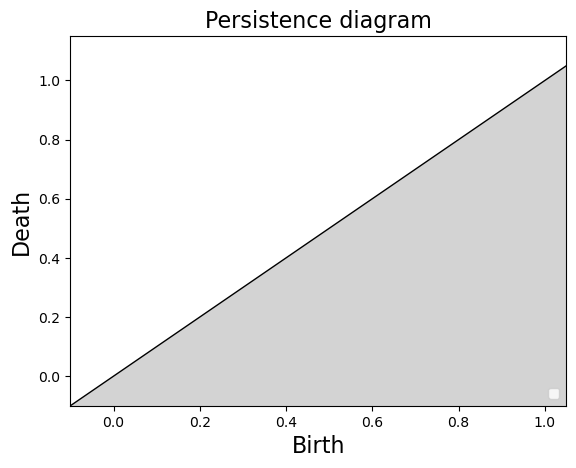

Identifying boundary points...
Identified boundary points (homology class 1 with high persistence):
[]


In [10]:
import numpy as np
import gudhi as gd

# Function to create points on a sphere
def create_sphere(center, radius, num_points=1000):
    points = []
    for _ in range(num_points):
        phi = np.random.uniform(0, np.pi)
        theta = np.random.uniform(0, 2 * np.pi)
        x = center[0] + radius * np.sin(phi) * np.cos(theta)
        y = center[1] + radius * np.sin(phi) * np.sin(theta)
        z = center[2] + radius * np.cos(phi)
        points.append([x, y, z])
    return np.array(points)

# Create two intersecting spheres
center1 = [0, 0, 0]
center2 = [0.5, 0.5, 0.5]  # Adjust this to control the intersection
radius = 1
sphere1 = create_sphere(center1, radius)
sphere2 = create_sphere(center2, radius)
print("Sphere 1 shape:", sphere1.shape)
print("Sphere 2 shape:", sphere2.shape)

# Combine the point clouds
combined_spheres = np.vstack((sphere1, sphere2))
print("Combined point cloud shape:", combined_spheres.shape)

# Compute the Vietoris-Rips complex and its persistent homology
rips_complex = gd.RipsComplex(points=combined_spheres, max_edge_length=2)
print("Rips complex result:", rips_complex)
simplex_tree = gd.SimplexTree()
print("Simplex tree result:", simplex_tree)

def process_point_cloud_incrementally(points, simplex_tree):
    for i, point in enumerate(points):
        simplex_tree.insert(point, filtration=i)
        if i % 100 == 0:
            print(f"Processed {i}/{len(points)} points")
            #if i == 1500:
             #   break

# Process the point cloud incrementally
process_point_cloud_incrementally(combined_spheres, simplex_tree)
diag=simplex_tree.persistence()
# Filter out the infinite persistence points which correspond to noise
finite_diags = [pt for pt in diag if pt[1][1] != float('inf')]
print("Number of finite persistence points:", len(finite_diags))

# Plot persistence diagram
print("Plotting persistence diagram...")
gd.plot_persistence_diagram(finite_diags)
plt.show()

# Identify the boundary of the intersection
# We look for points with high persistence in H1, which indicates a loop
print("Identifying boundary points...")
boundary_points = [pt for pt in finite_diags if pt[0] == 1 and pt[1][1] - pt[1][0] > 0.1]

print("Identified boundary points (homology class 1 with high persistence):")
print(boundary_points)

NameError: name 'combined_spheres' is not defined

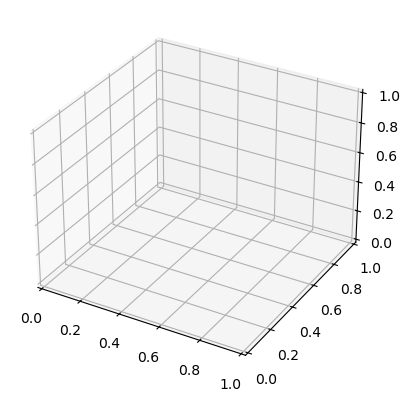

In [2]:
#plot the resulting point cloud
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(combined_spheres[:, 0], combined_spheres[:, 1], combined_spheres[:, 2])
plt.show()

#plot the boundary points
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(combined_spheres[:, 0], combined_spheres[:, 1], combined_spheres[:, 2])
ax.scatter([combined_spheres[i, 0] for i, _ in boundary_points], 
           [combined_spheres[i, 1] for i, _ in boundary_points], 
           [combined_spheres[i, 2] for i, _ in boundary_points], color='red')
plt.show()
